# Part 2: Exploratory Data Analysis (Netflix titles)

Data: `netflix_clean.csv`, the output of my Part 1 cleaning. It has one row per title.
Original dataset: "Netflix Movies and TV Shows" by Shivam Bansal on Kaggle (https://www.kaggle.com/datasets/shivamb/netflix-shows), a snapshot of titles listed on Netflix as of September 2021.

Every chart is saved as a PNG in a `charts/` folder, so you can use them as screenshots.

In [1]:
import os
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150)
    plt.show()

csv = "netflix_clean.csv" if os.path.exists("netflix_clean.csv") else "../netflix_clean.csv"
df = pd.read_csv(csv, parse_dates=["date_added"])
print(df.shape)
df.head()

(8787, 20)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,month_name,weekday_added,years_to_netflix,duration_min,seasons,genre_count,primary_genre,rating_group
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September,Saturday,1,90.0,NaN,1,Documentaries,Teens
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September,Friday,0,NaN,1.0,3,Crime TV Shows,Adults
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September,Friday,0,NaN,1.0,3,TV Dramas,Adults
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September,Wednesday,0,91.0,NaN,2,Children & Family Movies,Older Kids
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September,Friday,28,125.0,NaN,3,Dramas,Adults


## 1. Structure of the data
How many rows and columns, what types they are, and where values are missing.

In [2]:
df.info()
print()
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8787 entries, 0 to 8786
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   show_id           8787 non-null   object        
 1   type              8787 non-null   object        
 2   title             8787 non-null   object        
 3   director          8787 non-null   object        
 4   country           8787 non-null   object        
 5   date_added        8787 non-null   datetime64[ns]
 6   release_year      8787 non-null   int64         
 7   rating            8787 non-null   object        
 8   duration          8787 non-null   object        
 9   listed_in         8787 non-null   object        
 10  year_added        8787 non-null   int64         
 11  month_added       8787 non-null   int64         
 12  month_name        8787 non-null   object        
 13  weekday_added     8787 non-null   object        
 14  years_to_netflix  8787 n

`duration_min` is empty for TV shows and `seasons` is empty for movies. That is expected, not a data problem: movies have minutes, TV shows have seasons.

## 2. Movies vs TV shows

type
Movie      6124
TV Show    2663
Name: count, dtype: int64
type
Movie      69.7
TV Show    30.3
Name: count, dtype: float64


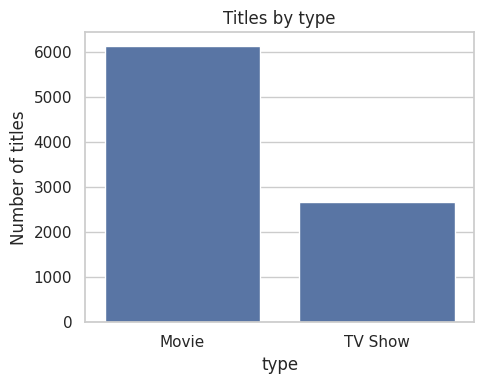

In [3]:
counts = df["type"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))
plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Titles by type")
plt.ylabel("Number of titles")
save("01_type_counts")

Observation: there are 6,124 movies (69.7%) and 2,663 TV shows (30.3%). The catalog is about two-thirds movies, so single-sitting content dominates even though series are what keep viewers coming back.

## 3. Countries
**Caveat:** the dataset has a single country label per title (Part 1 kept one value). Real co-productions are therefore counted under one country only, and 287 titles are `Unknown`.

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64
Unknown: 287


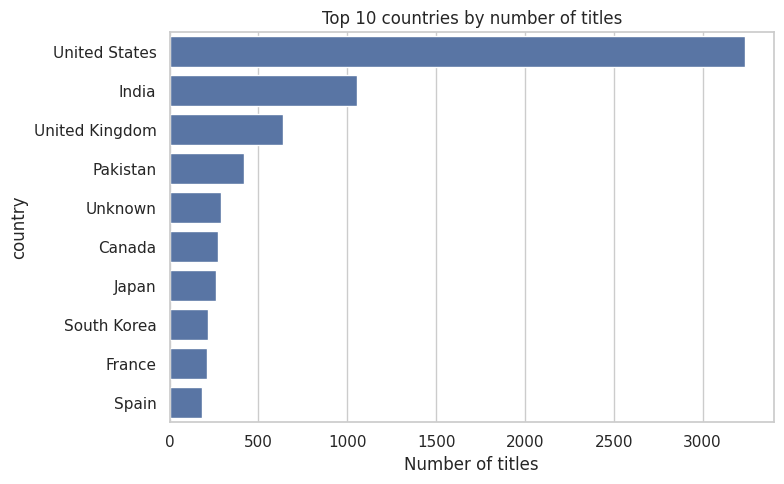

In [4]:
top_c = df["country"].value_counts().head(10)
print(top_c)
print("Unknown:", (df["country"] == "Unknown").sum())
plt.figure(figsize=(8, 5))
sns.barplot(x=top_c.values, y=top_c.index)
plt.title("Top 10 countries by number of titles")
plt.xlabel("Number of titles")
save("02_top_countries")

Observation: the United States (3,240), India (1,056) and the United Kingdom (638) lead. The US lead fits Netflix being an American company with its largest home-market catalog, and the single-label caveat adds to it: each title keeps only its first listed country, so co-productions count once and smaller partner countries are under-counted. 287 titles have no usable country label ("Unknown").

## 4. Ratings and genres

rating
TV-MA    3205
TV-14    2155
TV-PG     861
R         798
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
Name: count, dtype: int64


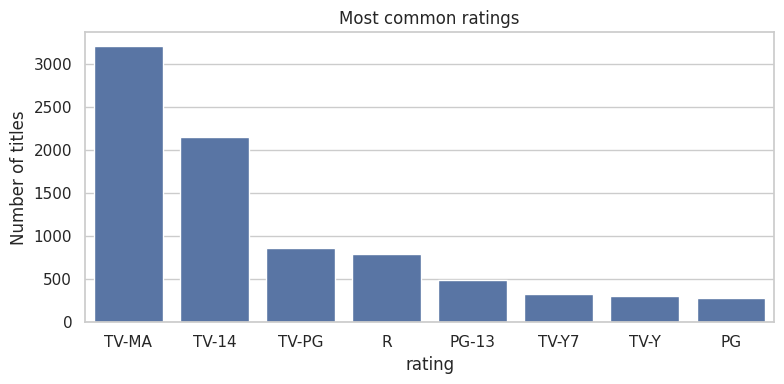

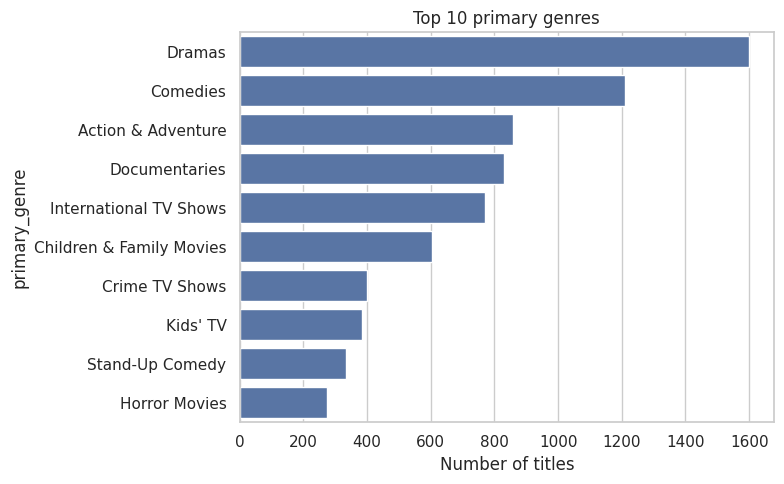

In [5]:
rate = df["rating"].value_counts().head(8)
print(rate)
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.index, y=rate.values)
plt.title("Most common ratings")
plt.ylabel("Number of titles")
save("03_ratings")

genres = df["primary_genre"].value_counts().head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=genres.values, y=genres.index)
plt.title("Top 10 primary genres")
plt.xlabel("Number of titles")
save("04_top_genres")

Observation: TV-MA is the biggest rating (3,205 titles), followed by TV-14 (2,155). Well over half the catalog is aimed at mature or teen audiences, so the catalog clearly targets adults and older teens rather than children.

## 5. Titles added per year
**Caveat:** the data ends on 25 Sep 2021, so 2021 is a partial year and its bar is not comparable with full years.

2021-09-25 00:00:00
year_added
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2014
2020    1879
2021    1498
dtype: int64


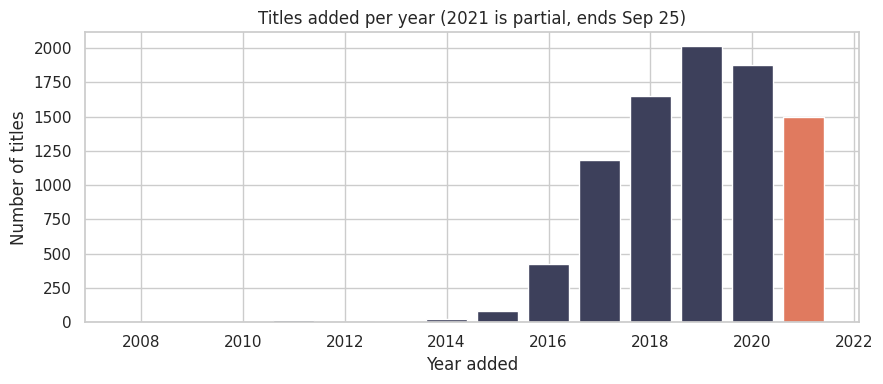

In [6]:
print(df["date_added"].max())
by_year = df.groupby("year_added").size()
print(by_year.tail(8))
colors = ["#e07a5f" if y == 2021 else "#3d405b" for y in by_year.index]
plt.figure(figsize=(9, 4))
plt.bar(by_year.index.astype(int), by_year.values, color=colors)
plt.title("Titles added per year (2021 is partial, ends Sep 25)")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
save("05_added_per_year")

Observation: additions peak at 2,014 in 2019 and stay high in 2020 (1,879). The 1,498 shown for 2021 is not comparable with full years, because the data ends on 25 September 2021 and roughly the last quarter is missing. The monthly counts below confirm additions continue right up to the cutoff, so the real slowdown is 2019 to 2020, not 2021.

In [7]:
monthly = df.groupby("month_name").size()
print(monthly.sort_values(ascending=False).head(5))

month_name
July         827
December     812
September    769
April        763
October      759
dtype: int64


## 6. Durations

count    6124.000000
mean       99.573645
std        28.280425
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_min, dtype: float64


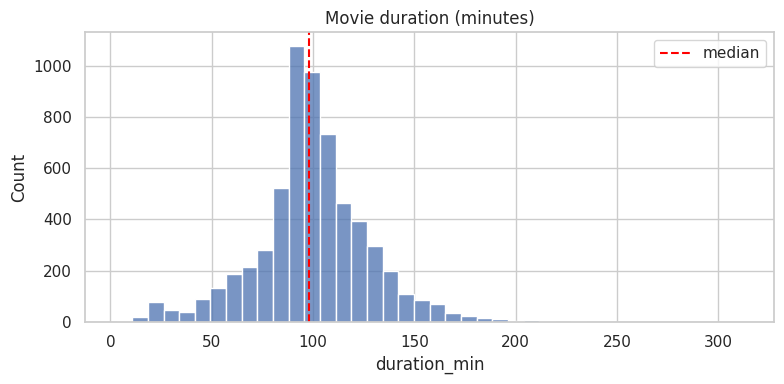

seasons
1.0     1790
2.0      421
3.0      198
4.0       94
5.0       64
6.0       33
7.0       23
8.0       17
9.0        9
10.0       6
11.0       1
12.0       2
13.0       2
15.0       2
17.0       1
Name: count, dtype: int64


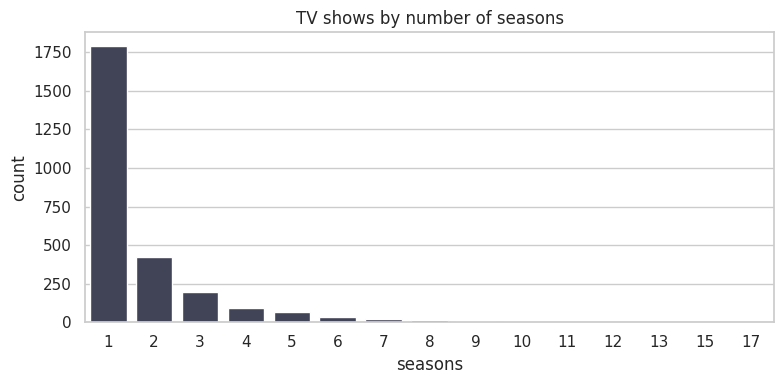

In [8]:
movies = df[df["type"] == "Movie"]
print(movies["duration_min"].describe())
plt.figure(figsize=(8, 4))
sns.histplot(movies["duration_min"], bins=40)
plt.axvline(movies["duration_min"].median(), color="red", linestyle="--", label="median")
plt.legend()
plt.title("Movie duration (minutes)")
save("06_movie_durations")

tv = df[df["type"] == "TV Show"]
print(tv["seasons"].value_counts().sort_index())
plt.figure(figsize=(8, 4))
sns.countplot(x=tv["seasons"].astype(int), color="#3d405b")
plt.title("TV shows by number of seasons")
save("07_tv_seasons")

Observation: the median movie runs 98 minutes (half of all movies sit between 87 and 114 minutes), and 1,790 of the 2,663 TV shows have a single season. The catalog favors standard feature-length films and short or limited series.

## 7. Data quality check: negative lags
`years_to_netflix` is the year added minus the release year. A negative value means a title was added to Netflix before its recorded release year. That is odd. I only flag these rows and **do not fix them** here.

In [9]:
neg = df[df["years_to_netflix"] < 0]
print(len(neg), "rows with a negative lag")
neg[["title", "type", "release_year", "year_added", "years_to_netflix"]]

14 rows with a negative lag


,title,type,release_year,year_added,years_to_netflix
3868,Hans Teeuwen: Real Rancour,Movie,2018,2017,-1
5135,Incoming,Movie,2019,2018,-1
5175,Jack Taylor,TV Show,2016,2013,-3
6945,Hilda,TV Show,2021,2020,-1
6989,Polly Pocket,TV Show,2021,2020,-1
7352,Love Is Blind,TV Show,2021,2020,-1
7433,Fuller House,TV Show,2020,2019,-1
7481,Maradona in Mexico,TV Show,2020,2019,-1
7514,BoJack Horseman,TV Show,2020,2019,-1
7534,The Hook Up Plan,TV Show,2020,2019,-1


A negative lag means the recorded year of addition is earlier than the release year, which is impossible for a normal catalog addition. The likely cause is a mistyped release year in the source data, or a title listed ahead of its release. With only 14 rows out of 8,787, I flag them here and leave them unchanged; they are too few to affect any result in this analysis.

## Findings summary

- Catalog mix: 6,124 movies (69.7%) against 2,663 TV shows (30.3%); films dominate the catalog.
- Geography: the United States (3,240), India (1,056) and the United Kingdom (638) lead. Each title keeps only one country label and 287 titles are "Unknown", so these counts understate co-productions.
- Growth: yearly additions grew from 24 in 2014 to a peak of 2,014 in 2019, then eased to 1,879 in 2020. The 1,498 for 2021 covers only up to 25 September, so it is a partial year.
- Content: TV-MA is the largest rating (3,205 titles); the median movie runs 98 minutes; most TV shows (1,790 of 2,663) have one season.
- Data quality: 14 titles have a negative release-to-addition lag; they are flagged, not fixed, and are too few to change the findings.

Source: "Netflix Movies and TV Shows" by Shivam Bansal on Kaggle (https://www.kaggle.com/datasets/shivamb/netflix-shows), a snapshot of titles listed on Netflix as of September 2021.